# [TCGA WGBS, PMD and Solo-WCGW CpGs](https://zwdzwd.github.io/pmd)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2022-02-27
> - Modified: 2025-05-03

# 1. Experimental Design

> TCGA WGBS, PMD and Solo-WCGW CpGs, Partially methylated domains (PMDs)
> - Zhou, W., Dinh, H.Q., Ramjan, Z. et al. DNA methylation loss in late-replicating domains is linked to mitotic cell division. Nat Genet 50, 591–602 (2018). https://doi.org/10.1038/s41588-018-0073-4.
> - WGBS, EZ DNA Methylation kit (Zymo Research)
> - Illumina HiSeq 2000

<figure style="text-align: center; margin: 1em 0;">
    <img src="https://media.springernature.com/full/springer-static/image/art%3A10.1038%2Fs41588-018-0073-4/MediaObjects/41588_2018_73_Fig1_HTML.jpg" 
         alt="Solo-WCGW CpGs are prone to hypomethylation."
         style="background: white; max-width: 100%; height: auto; border-radius: 4px;" />
    <figcaption style="font-size: 1em; margin-top: 8px;">
        Solo-WCGW CpGs are prone to hypomethylation.
    </figcaption>
</figure>

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/wgbs_Hs_TCGA_soloWCGW"

gtf_file <- "~/reference/Homo_sapiens/hg38/gencode.v48.annotation.gtf"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg38))
genome <- BSgenome.Hsapiens.UCSC.hg38

suppressPackageStartupMessages(library(TxDb.Hsapiens.UCSC.hg38.knownGene))
txdb <- TxDb.Hsapiens.UCSC.hg38.knownGene

# 2. Import Data

## 1). Import PMDs & HMDs

In [4]:
# PMDs and HMDs region
regions <- file.path(data_dir, "Solo_WCGW_CpGs", "PMD_coordinates_hg38.bed") |>
    read.table(
        header = FALSE, sep = "\t", stringsAsFactors = FALSE, 
        col.names = c("chr", "start", "end", "score", "class", "common")) |>
    as("GRanges")

regions

PMDs <- regions[regions$common == "commonPMD", ] |> reduce()
HMDs <- regions[regions$common == "commonHMD", ] |> reduce()

GRanges object with 27679 ranges and 3 metadata columns:
          seqnames              ranges strand |     score       class
             <Rle>           <IRanges>  <Rle> | <numeric> <character>
      [1]     chr1            0-100000      * | 0.2205086         PMD
      [2]     chr1       100000-200000      * | 0.3219724         PMD
      [3]     chr1       200000-300000      * | 0.0784889         HMD
      [4]     chr1       300000-400000      * |        NA        <NA>
      [5]     chr1       400000-500000      * |        NA        <NA>
      ...      ...                 ...    ... .       ...         ...
  [27675]     chr9 137900000-138000000      * |  0.188840         PMD
  [27676]     chr9 138000000-138100000      * |  0.200903         PMD
  [27677]     chr9 138100000-138200000      * |  0.165706         PMD
  [27678]     chr9 138200000-138300000      * |  0.267407         PMD
  [27679]     chr9 138300000-138400000      * |        NA        <NA>
               common
          <

## 2). Import bigwig

In [5]:
# Load bigwig (bw) file as GRanges
load_bigwig <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE,
    blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [6]:
file_pattern <- "(.*)\\.vcf\\.gz_cg_cov5\\.bw$"

bw_files <- file.path(
    data_dir, "TCGA_Cancer_Methylomes", "TCGA_WGBS_hg38_bw_mindepth5") |>
    list.files(pattern = "^TCGA_COAD.*\\.bw$", full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

paste(names(bw_files), basename(bw_files), sep = ": ") |> cat(sep = "\n")

TCGA_COAD_3518: TCGA_COAD_3518.vcf.gz_cg_cov5.bw
TCGA_COAD_A00R: TCGA_COAD_A00R.vcf.gz_cg_cov5.bw
TCGA_COAD_N3518: TCGA_COAD_N3518.vcf.gz_cg_cov5.bw


In [7]:
sample_idx <- c('TCGA_COAD_N3518', 'TCGA_COAD_3518', 'TCGA_COAD_A00R')

signals_list <- lapply(bw_files, load_bigwig, dropSex = FALSE)
signals_list <- signals_list[sample_idx]

signals_list[1]

$TCGA_COAD_N3518
GRanges object with 25388068 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1       16243-16244      * |     0.710
         [2]     chr1       17378-17379      * |     1.000
         [3]     chr1       17406-17407      * |     1.000
         [4]     chr1       17452-17453      * |     0.958
         [5]     chr1       17478-17479      * |     0.967
         ...      ...               ...    ... .       ...
  [25388064]     chrY 56886944-56886945      * |     0.000
  [25388065]     chrY 56886954-56886955      * |     0.535
  [25388066]     chrY 56887025-56887026      * |     0.959
  [25388067]     chrY 56887089-56887090      * |     0.841
  [25388068]     chrY 56887099-56887100      * |     0.929
  -------
  seqinfo: 24 sequences from an unspecified genome


# 3. Evaluate Library Quality

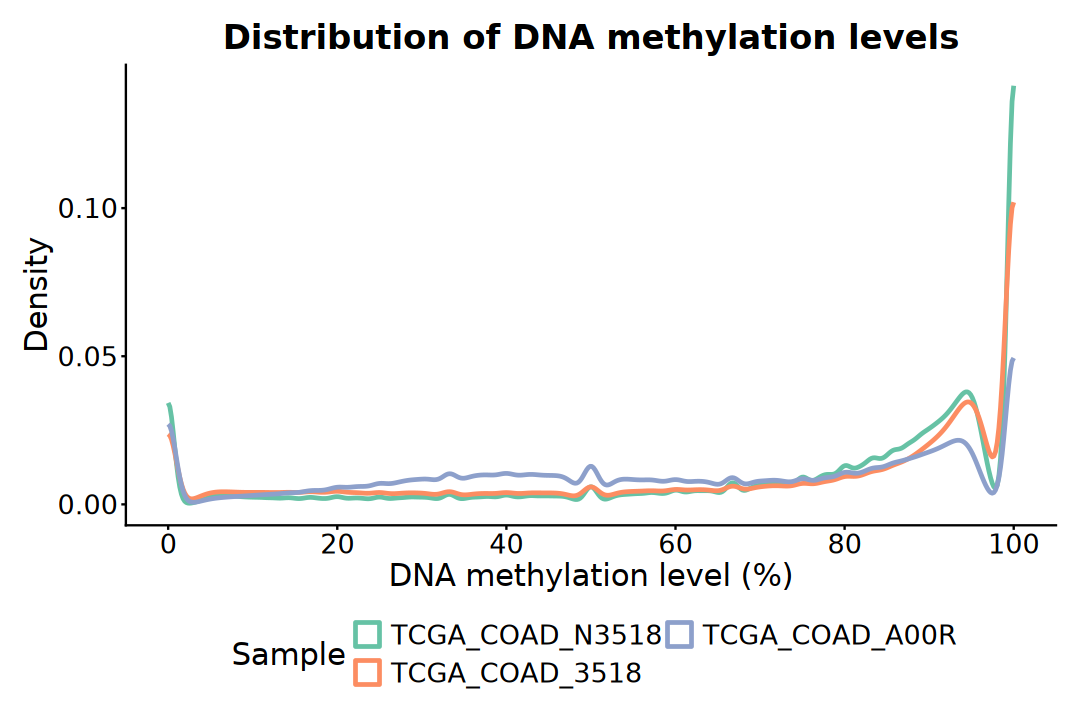

In [8]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(signals_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, score) |>
    dplyr::mutate(score = score * 100) |>
    dplyr::mutate(sample = factor(sample, levels = names(signals_list))) |>
    ggplot(aes(x = score, color = sample)) +
    geom_density(linewidth = 1) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Density", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

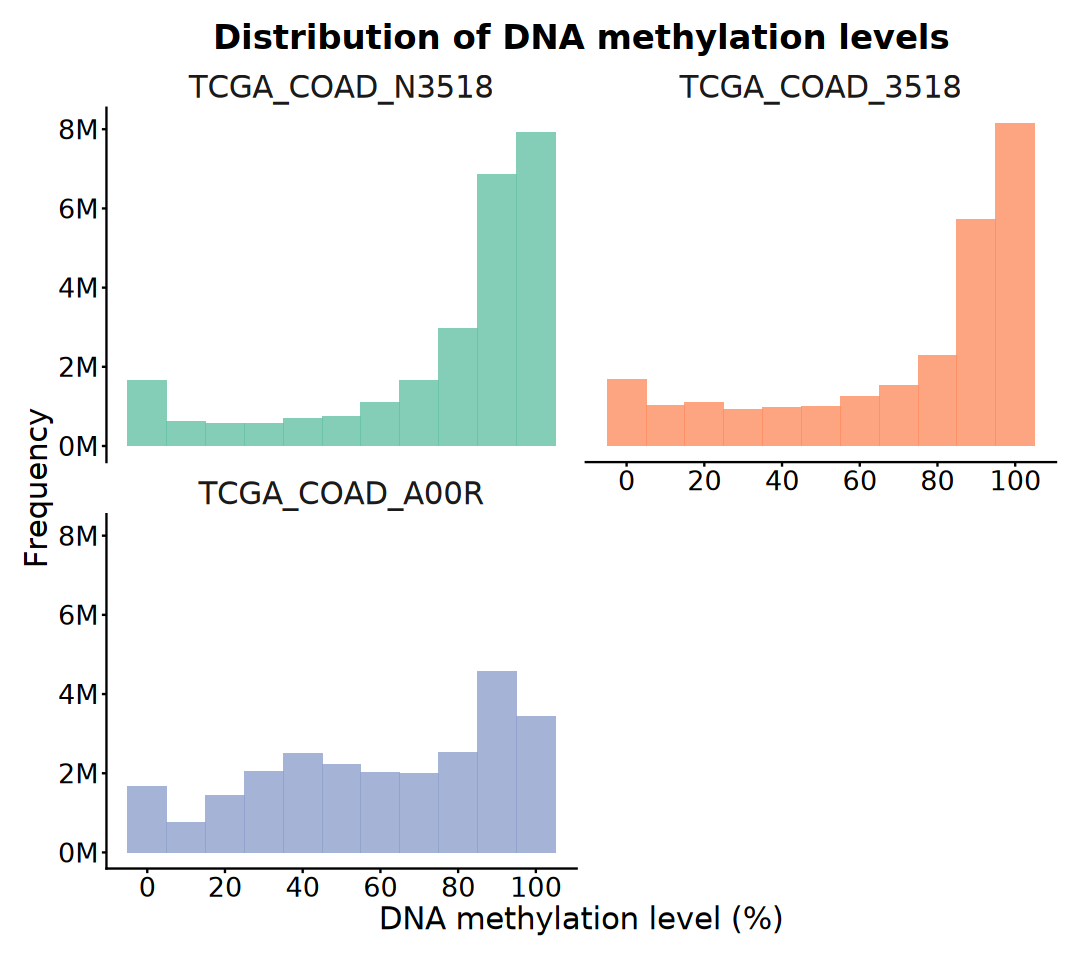

In [9]:
options(repr.plot.width = 9, repr.plot.height = 8)

map(signals_list, ~ data.frame(meth = mcols(.x)$score * 100)) |>
    purrr::list_rbind(names_to = "sample") |>
    dplyr::mutate(sample = factor(sample, levels = names(signals_list))) |>
    ggplot(aes(x = meth, fill = sample)) +
    geom_histogram(binwidth = 10, position = "identity", alpha = 0.8) +
    facet_wrap( ~ sample, ncol = 2) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Standard Plot

In [10]:
plot_df <- data.frame(
    sample = names(signals_list), 
    number = sapply(signals_list, length),
    mean = sapply(signals_list, \(gr) mean(mcols(gr)$score))) |>
    mutate(mean = mean * 100, Group = c("Normal", "Cancer", "Cancer"))

plot_df

,sample,number,mean,Group
,<chr>,<int>,<dbl>,<chr>
TCGA_COAD_N3518,TCGA_COAD_N3518,25388068,76.14659,Normal
TCGA_COAD_3518,TCGA_COAD_3518,25567187,72.04259,Cancer
TCGA_COAD_A00R,TCGA_COAD_A00R,25187567,60.84073,Cancer


## 2). Density Scatter Plot

In [11]:
common_cpg <- Reduce(function(x, y) {
    x[findOverlaps(x, y, type = "equal") |> queryHits()]
}, signals_list) |> granges()

common_cpg

GRanges object with 24323256 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1       17452-17453      *
         [2]     chr1       17478-17479      *
         [3]     chr1       17483-17484      *
         [4]     chr1       17492-17493      *
         [5]     chr1       17562-17563      *
         ...      ...               ...    ...
  [24323252]     chrY 56886944-56886945      *
  [24323253]     chrY 56886954-56886955      *
  [24323254]     chrY 56887025-56887026      *
  [24323255]     chrY 56887089-56887090      *
  [24323256]     chrY 56887099-56887100      *
  -------
  seqinfo: 24 sequences from an unspecified genome

In [12]:
meth_common <- lapply(signals_list, function(gr) {
    hits <- findOverlaps(common_cpg, gr, type = "equal")
    meth <- rep(NA_real_, length(common_cpg))
    meth[queryHits(hits)] <- gr$score[subjectHits(hits)]
    meth
})

meth_common <- as.data.frame(meth_common)
names(meth_common) <- names(signals_list)

In [13]:
sample_pairs <- combn(names(signals_list), 2, simplify = FALSE)

plot_list <- lapply(sample_pairs, function(pair) {
    ggplot(meth_common, aes(.data[[pair[1]]], .data[[pair[2]]])) +
        geom_bin2d(bins = 100) +
        geom_abline(
            slope = 1, intercept = 0, linetype = "dashed",
            color = "lightcoral", linewidth = 1) +
        scale_fill_gradientn(
            colors = viridis(256), trans = "log10", name = "Count (log10)") +
        coord_fixed() +
        labs(title = "DNA methylation comparison", x = pair[1], y = pair[2]) +
        theme_bw() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            legend.position = "right",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
})

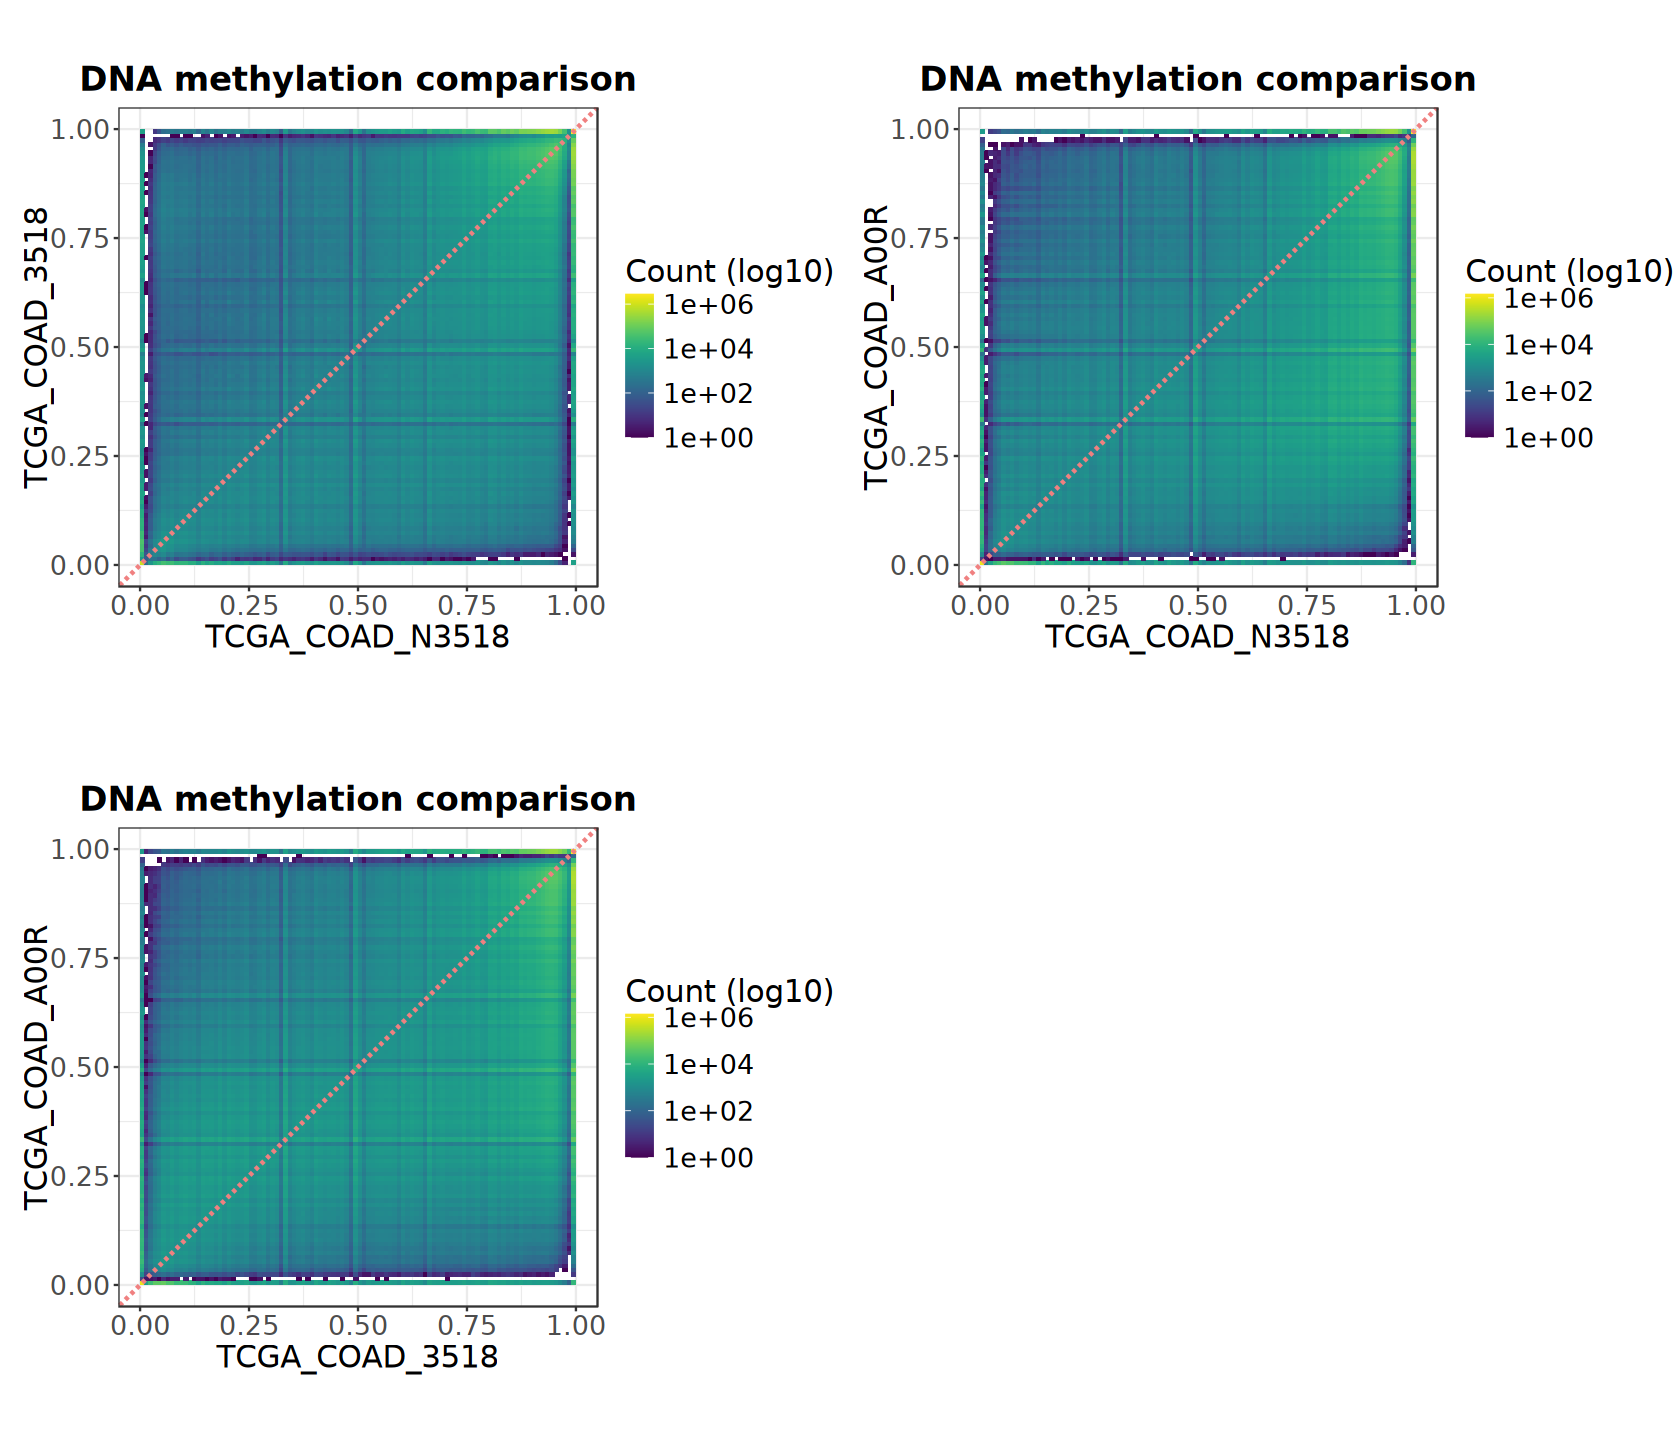

In [14]:
options(repr.plot.width = 14, repr.plot.height = 12)

plot_grid(plotlist = plot_list, nrow = 2, ncol = 2)

In [15]:
plot_methylation_comparison <- function(plot_df, sample_x, sample_y) {
    # Linear regression
    fit <- lm(methy_y ~ methy_x, data = plot_df)

    # Spearman correlation
    cor_res <- cor.test(
        plot_df$methy_x, plot_df$methy_y, method = "spearman", exact = FALSE)

    # scatter plot
    smoothScatter(
        plot_df$methy_x, plot_df$methy_y,
        colramp = colorRampPalette(brewer.pal(9, "Blues")),
        xlab = sample_x, ylab = sample_y, cex = 0)
    abline(a = 0, b = 1, col = "darkblue", lty = 2, lwd = 3)
    abline(fit, col = "darkred", lty = 2, lwd = 3)
    legend(
        "topleft", lty = 2, lwd = 2, col = 'black', border = NA, 
        text.col = "black", box.col = NA, bg = NA,
        legend = c(
            paste0("Linear slope: ", round(coef(fit)[2], 2)),
            paste0("Spearman \u03c1: ", round(cor_res$estimate, 2)),
            paste0("P-value: ", format.pval(
                cor_res$p.value, digits = 2, eps = 1e-100))))
}

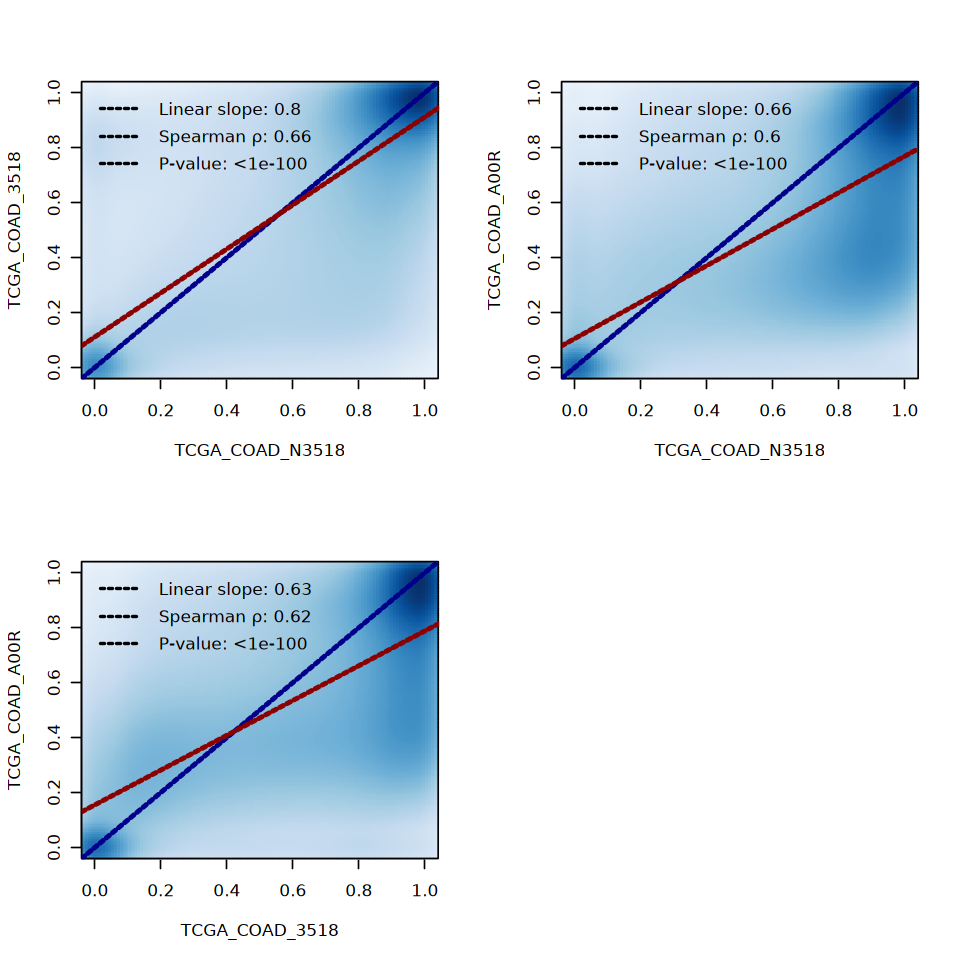

In [16]:
options(repr.plot.width = 8, repr.plot.height = 8)

par(mfrow = c(2, 2))

for (pair in combn(names(signals_list), 2, simplify = FALSE)) {
    plot_df <- data.frame(
        methy_x = meth_common[[pair[1]]],
        methy_y = meth_common[[pair[2]]])
    plot_methylation_comparison(plot_df, pair[1], pair[2])
}

## 3). Circular Genome-wide Plot

In [17]:
suppressPackageStartupMessages(library(circlize))

In [18]:
# 1. Read and process chromosome sizes
chrom_sizes <- seqlengths(genome)
standard_chromosome <- c(paste0("chr", 1:22), "chrX", "chrY")
chrom_sizes <- chrom_sizes[names(chrom_sizes) %in% standard_chromosome]

# 2. Generate genomic bins (1Mb window)
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
bins <- trim(bins)

# 3. Calculate gene density per bin
GENES <- genes(txdb)
bins$gene_density <- countOverlaps(bins, GENES)

  2169 genes were dropped because they have exons located on both strands of
  the same reference sequence or on more than one reference sequence, so cannot
  be represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [19]:
# 4. Calculate mean methylation level for each bins.
bin_stats_list <- lapply(names(signals_list), function(idx) {
    gr <- signals_list[[idx]]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        score = gr$score[queryHits(hits)])

    bin_stats <- df[, .(
        meth = mean(score, na.rm = TRUE) * 100), by = bin_idx]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

In [20]:
# 5. Prepare data frames for plotting
bin_df <- do.call(c, bin_stats_list) |> as.data.frame() |>
    dplyr::select(chr = seqnames, start, end, sample, gene_density, meth) |>
    pivot_wider(
        id_cols = c("chr", "start", "end", gene_density),
        names_from = "sample", values_from = "meth") |>
    dplyr::mutate(chr = factor(chr, levels = standard_chromosome)) |>
    dplyr::arrange(chr, start)

head(bin_df)

chr,start,end,gene_density,TCGA_COAD_N3518,TCGA_COAD_3518,TCGA_COAD_A00R
<fct>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
chr1,1,1000000,40,48.98006,52.22746,49.51750
chr1,1000001,2000000,63,64.04671,64.78872,64.49887
chr1,2000001,3000000,18,71.88356,70.69209,65.10743
chr1,3000001,4000000,27,71.85437,70.30360,70.57237
chr1,4000001,5000000,8,74.23906,72.21279,48.71876
chr1,5000001,6000000,7,75.99004,69.98980,55.56754


Warning message:
“Some of the regions have end position values larger than the end of the
chromosomes.”


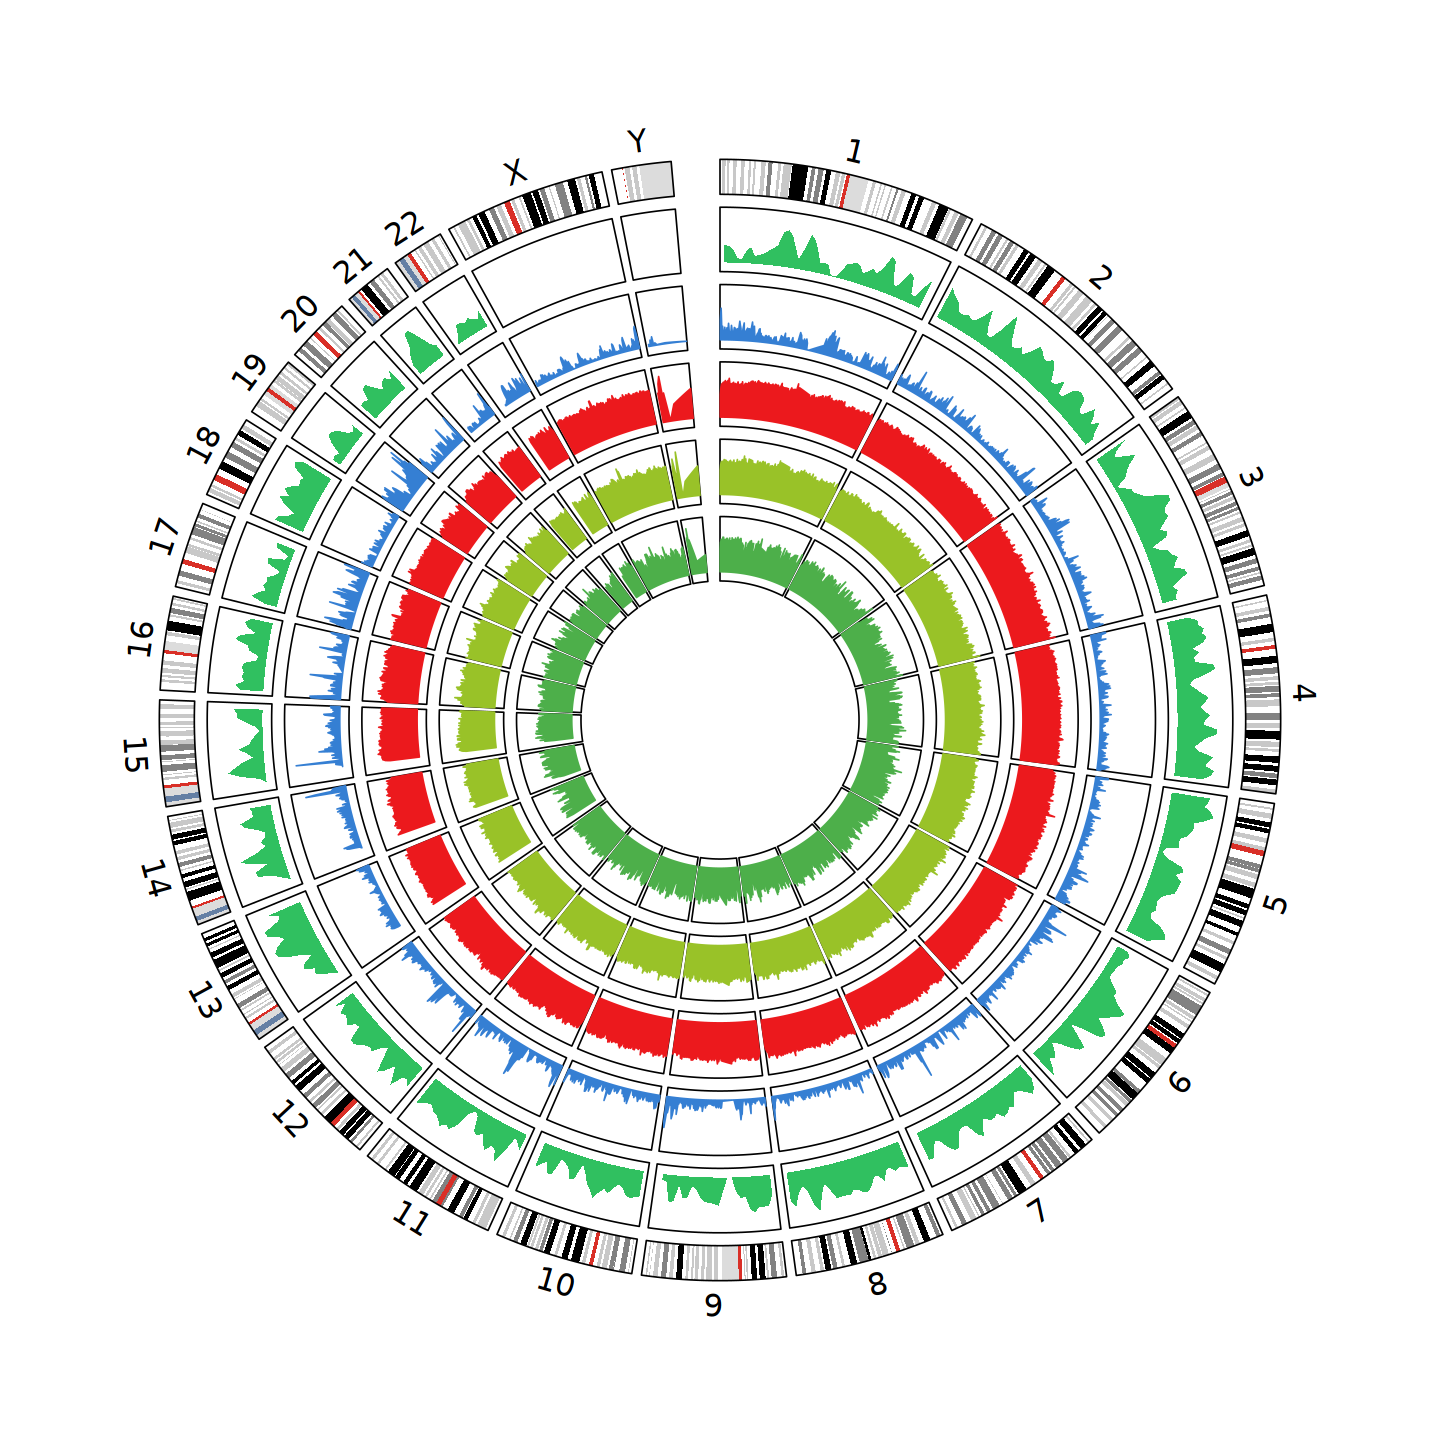

In [21]:
# 6. Setup Circos plot parameters
options(repr.plot.width = 12, repr.plot.height = 12)

circos.par(
    start.degree = 90, track.margin = c(0.01, 0.01),
    gap.after = c(rep(1, length(standard_chromosome) - 1), 5))

circos.initializeWithIdeogram(
    species = "hg38", 
    plotType = c("ideogram", "labels"),
    chromosome.index = standard_chromosome,
    ideogram.height = convert_height(4, "mm"),
    track.height = 0.1, labels.cex = 1.5, axis.labels.cex = 0.6)

circos.genomicDensity(
    as.data.frame(PMDs), col = c("#30c060"), track.height = 0.1)
# circos.genomicDensity(
#     as.data.frame(GENES), col = c("#357fd3"), track.height = 0.1)

# 7. Define helper function for plotting signal tracks
plot_peak_track <- function(
    data_col, color, ylimit = NULL, track_height = 0.1) {

    df_track <- bin_df[, c("chr", "start", "end", data_col)]
    df_track <- df_track[!is.na(df_track[[data_col]]), ]

    circos.genomicTrack(
        df_track, track.height = track_height, ylim = ylimit,
        panel.fun = function(region, value, ...) {
            circos.genomicLines(
                region, value,
                area = TRUE, baseline = 0,
                col = color, border = color)
        })
}

# 8. Plot individual signal tracks
plot_peak_track("gene_density", color = "#357fd3")
plot_peak_track(names(signals_list)[1], color = "#ec191d", ylimit = c(0, 100))
plot_peak_track(names(signals_list)[2], color = "#99c228", ylimit = c(0, 100))
plot_peak_track(names(signals_list)[3], color = "#4daf4a", ylimit = c(0, 100))

# 9. Clear Circos parameters (crucial for rendering subsequent plots cleanly)
circos.clear()

## 4). Genomic Signal Plot

In [22]:
chr_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chr_idx]
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
names(bins) <- floor((start(bins) + end(bins)) / 2)

In [23]:
pmd_df <- PMDs |> as.data.frame() |>
    filter(seqnames == "chr2") |>
    transmute(xmin = start, xmax = end, ymin = 95, ymax = 100)

In [24]:
bin_stats_list <- lapply(names(signals_list), function(idx) {
    gr <- signals_list[[idx]]
    gr <- gr[seqnames(gr) == chr_idx]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        score = mcols(gr)$score[queryHits(hits)])

    bin_stats <- df[, .(
        meth = mean(score, na.rm = TRUE) * 100), by = bin_idx]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

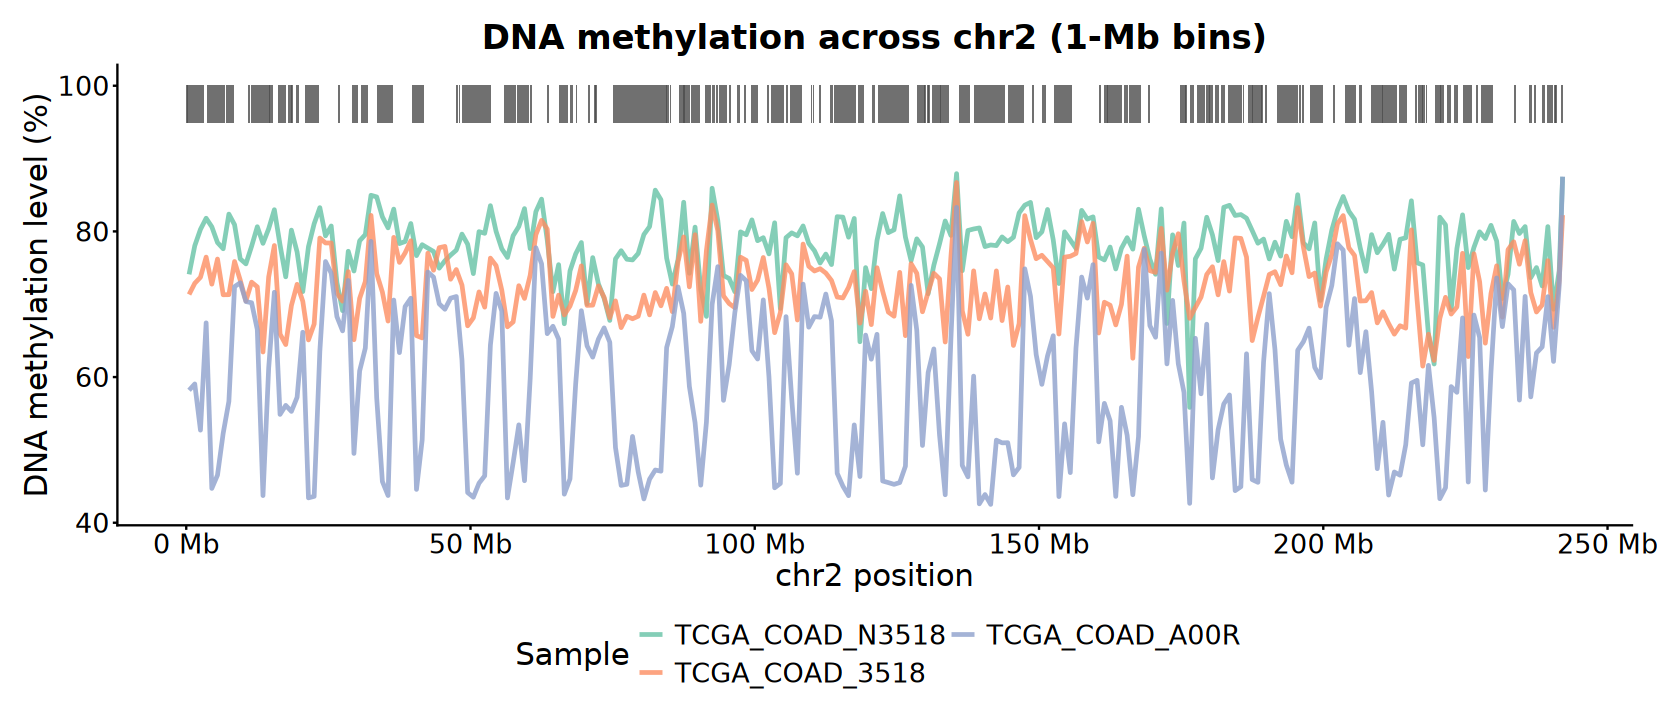

In [25]:
options(repr.plot.width = 14, repr.plot.height = 6)

do.call(c, bin_stats_list) |> as.data.frame() |> 
    mutate(position = (start + end) / 2) |>
    mutate(sample = factor(sample, levels = names(signals_list))) |>
ggplot(aes(x = position, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_rect(
        data = pmd_df, 
        aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax),
        inherit.aes = FALSE, fill = "grey30", alpha = 0.8) +
    scale_x_continuous(
        limits = c(1, chrom_sizes), breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = paste0("DNA methylation across ", chr_idx, " (1-Mb bins)"),
        x = paste0(chr_idx, " position"), 
        y = "DNA methylation level (%)",
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 2, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Methylation Profiles

In [26]:
gtf <- import(gtf_file)

GENES <- subset(
    gtf, type == "gene" & gene_type == "protein_coding",
    select = c("gene_id", "gene_name")
)

PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [27]:
CGI <- read.table(
    "~/reference/Homo_sapiens/hg38/ucsc/cpgIslandExt.txt", 
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length", 
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [28]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  12398    7698 


    Promoter non_Promoter 
       10957        11115 

### a). Genes

In [29]:
gene_mat_List <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [30]:
partition <- PROMOTERS$CGI_status

col_cluster <- c(CGI  = "#756BB1", non_CGI = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0,  0.5, 1),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "CpG status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [31]:
ht_list <- Heatmap(
    partition, name = "Genes", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(gene_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        gene_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 1)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

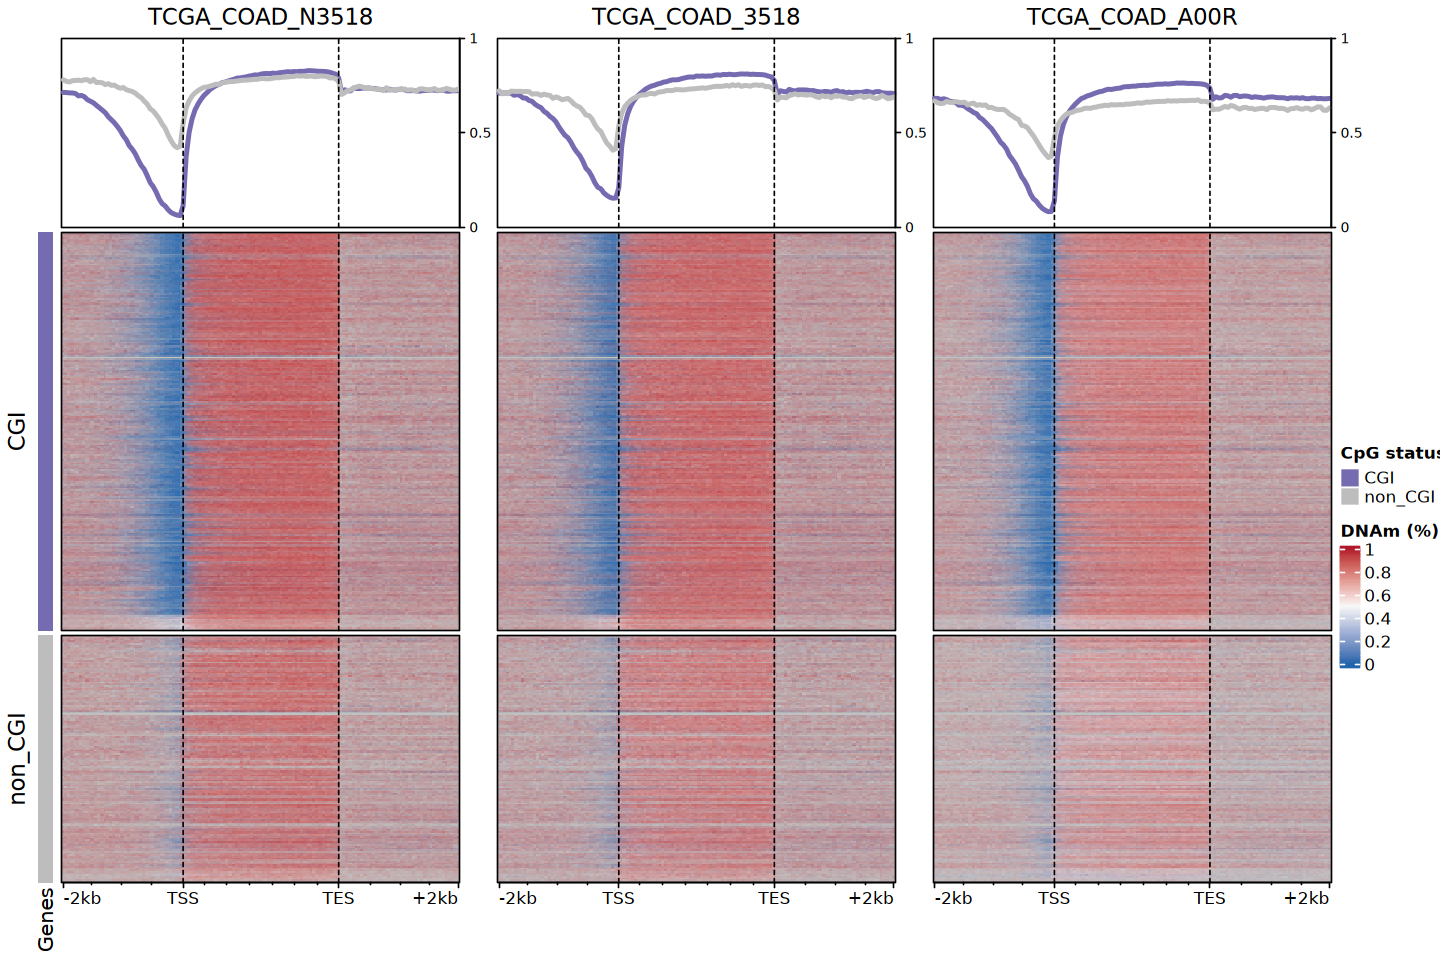

In [32]:
options(repr.plot.width = 12, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(gene_mat_List))), "mm"))

In [33]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(sample = factor(sample, levels = names(signals_list))) |>
    mutate(pos = factor(pos, levels = position_index))


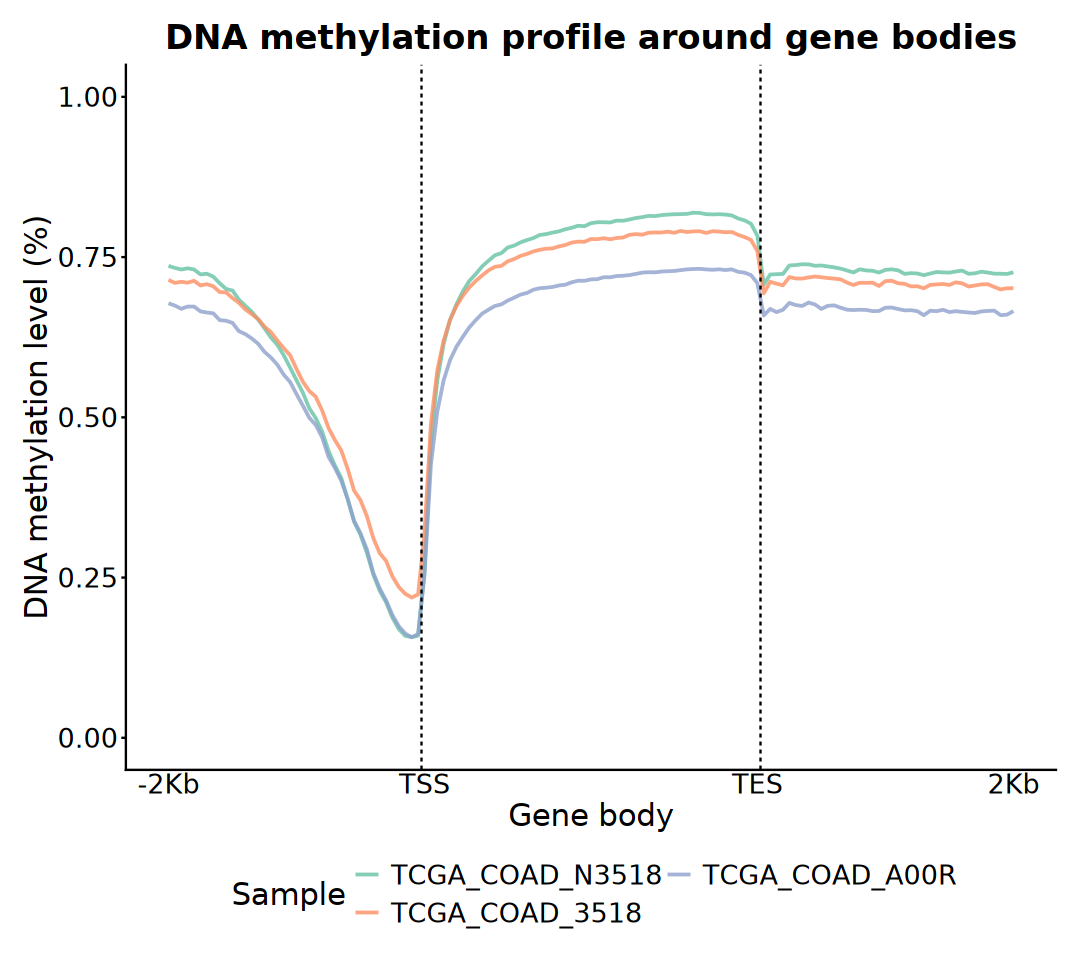

In [34]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 1)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [35]:
cgi_mat_List <- lapply(
    signals_list, normalizeToMatrix, CGI, value_column = "score",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [36]:
partition <- CGI$Promoter_status

col_cluster <- c(Promoter  = "#1B9E77", non_Promoter = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 0.5, 1),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "Promoter status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [37]:
ht_list <- Heatmap(
    partition, name = "CGI", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(cgi_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        cgi_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-4kb", "start", "end", "+4kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 1)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

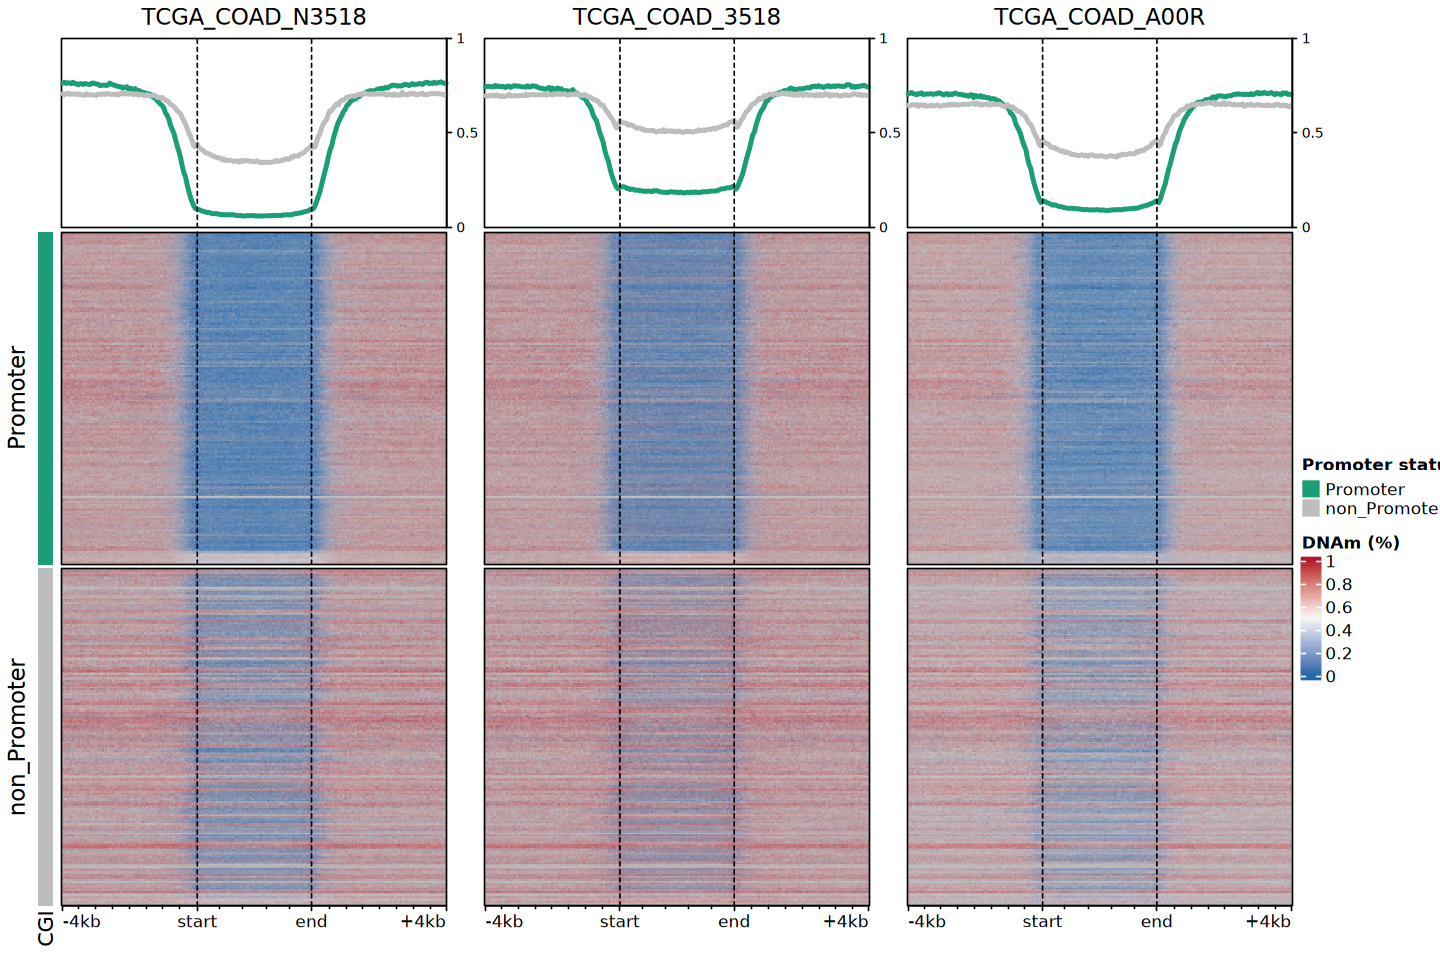

In [38]:
options(repr.plot.width = 12, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(cgi_mat_List))), "mm"))

In [39]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(sample = factor(sample, levels = names(signals_list))) |>
    mutate(pos = factor(pos, levels = position_index))

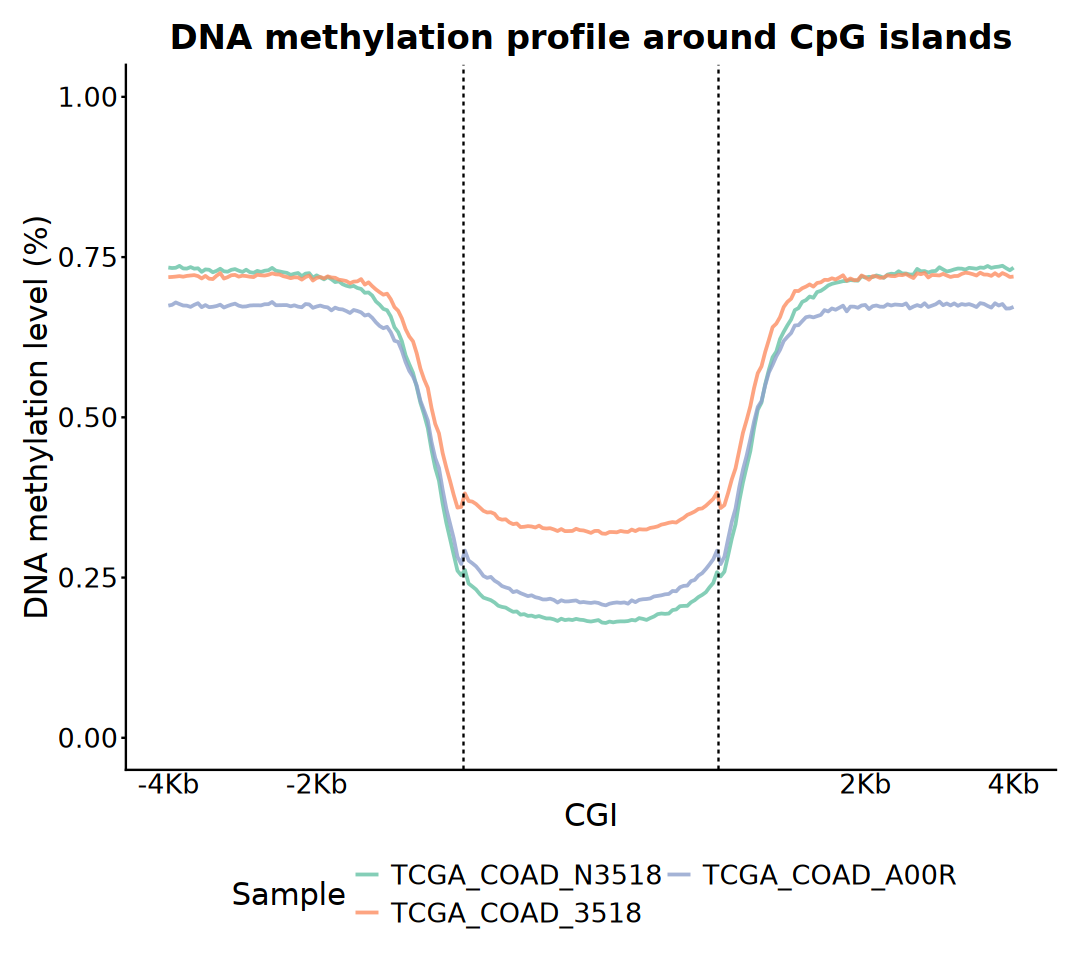

In [40]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb"), 
        expand = c(0.05, 0.05)) +
    coord_cartesian(ylim = c(0, 1)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

In [41]:
get_region_data <- function(
    gr, region, sample_id, method = c("mean", "ratio"),
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)
    region_mean <- rep(NA_real_, length(region))

    if (length(hits) == 0) {
        mcols(region)[[sample_id]] <- region_mean
        return(region)
    }

    cpg_idx <- queryHits(hits)
    region_idx <- subjectHits(hits)

    if (method == "mean") {
        vals <- mcols(gr)[[meth_col]]
        region_mean <- tapply(vals[cpg_idx], region_idx, mean, na.rm = TRUE)
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    } else {
        numCs <- mcols(gr)[[numCs_col]]
        numTs <- mcols(gr)[[numTs_col]]
        sumCs <- tapply(numCs[cpg_idx], region_idx, sum, na.rm = TRUE)
        sumTs <- tapply(numTs[cpg_idx], region_idx, sum, na.rm = TRUE)
        region_mean <- sumCs / (sumCs + sumTs) * 100
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    }
    mcols(region)[[sample_id]] <- result
    return(region)
}

In [42]:
region_mat <- Reduce(function(region, sample) {
    get_region_data(
        gr = signals_list[[sample]], region = region, sample_id = sample,
        method = "mean", meth_col = "score")
    }, names(signals_list), init = CGI)

In [43]:
plot_df <- region_mat |> mcols() |> as.data.frame() |>
    dplyr::select(Promoter_status, names(signals_list)) |>
    pivot_longer(
        cols = - Promoter_status, names_to = "sample", values_to = "meth") |>
    mutate(
        meth = meth * 100, 
        sample = factor(sample, levels = names(signals_list)))

head(plot_df)

Promoter_status,sample,meth
<fct>,<fct>,<dbl>
non_Promoter,TCGA_COAD_N3518,NA
non_Promoter,TCGA_COAD_3518,NA
non_Promoter,TCGA_COAD_A00R,NA
non_Promoter,TCGA_COAD_N3518,98.02000
non_Promoter,TCGA_COAD_3518,92.39231
non_Promoter,TCGA_COAD_A00R,NA


In [44]:
suppressPackageStartupMessages(library(ggridges))

Picking joint bandwidth of 1.57

Picking joint bandwidth of 5.41



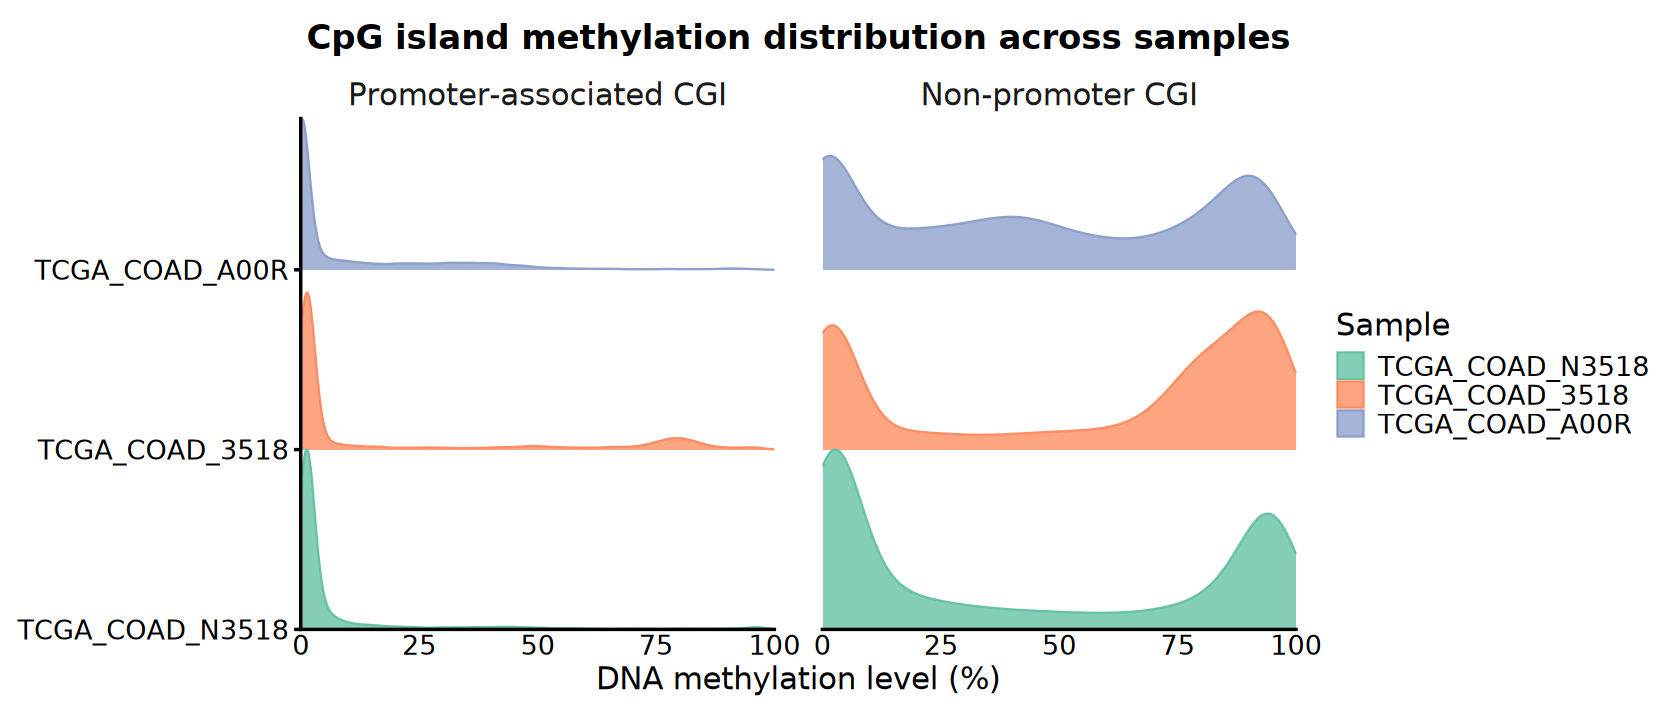

In [45]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(plot_df, aes(x = meth, y = sample)) +
    geom_density_ridges(
        aes(color = sample, fill = sample), alpha = 0.8, 
        scale = 1, na.rm = TRUE) +
    facet_wrap(~ Promoter_status, labeller = labeller(
        Promoter_status = c(
            "Promoter" = "Promoter-associated CGI",
            "non_Promoter" = "Non-promoter CGI"))) +
    scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL, 
        color = "Sample", fill = "Sample") +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

## 6). DNAm Distribution

In [46]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  2169 genes were dropped because they have exons located on both strands of
  the same reference sequence or on more than one reference sequence, so cannot
  be represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 8 out-of-bound ranges located on sequences
  chr4_GL000257v2_alt, chr16_KI270728v1_random, chr22_KI270731v1_random,
  chr3_GL000221v1_random, chr1_KI270706v1_random, chr16_GL383556v1_alt, and
  chrUn_KI270748v1. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information.”
Warning messa

In [47]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [48]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [49]:
get_profile_data <- function(
    gr, region, region_id, bin = 50, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)

    if(length(hits) == 0) return(NULL)

    gr_sub <- gr[queryHits(hits)]
    region_sub <- region[subjectHits(hits)]

    rel_pos <- (start(gr_sub) - start(region_sub)) / width(region_sub)
    is_minus <- as.character(strand(region_sub)) == "-"
    rel_pos[is_minus] <- 1 - rel_pos[is_minus]

    bin_idx <- ceiling(rel_pos * bin)
    bin_idx[bin_idx == 0] <- 1
    bin_idx[bin_idx > bin] <- bin

    if (method == "mean") {
        vals <- mcols(gr_sub)[[meth_col]]
        mean <- mean(vals, na.rm = TRUE)
        df <- tibble(bin = bin_idx, meth = vals) |> 
            group_by(bin) |>
            summarise(mean = mean(meth, na.rm = TRUE), .groups = "drop") |>
            mutate(region = region_id)
    } else if (method == "ratio") {
        numCs <- mcols(gr_sub)[[numCs_col]]
        numTs <- mcols(gr_sub)[[numTs_col]]
        df <- tibble(bin = bin_idx, numCs = numCs, numTs = numTs) |>
            group_by(bin) |>
            summarise(
                mean = sum(numCs) / sum(numCs + numTs) * 100, 
                .groups = "drop") |>
            mutate(region = region_id)
    }

    return(df)
}

In [50]:
region_index <- c(
    "Promoter", "FiveUTR", "Exon", "Intron", "ThreeUTR", 
    "Downstream", "Intergenic")

profiles_list <- list()

for (sample_idx in names(signals_list)) {
    meth <- signals_list[[sample_idx]]
    result <- lapply(region_index, function(idx) {
        region <- region_list[[idx]]
        df <- get_profile_data(
            meth, region, idx, bin = 50, method = "mean", 
            meth_col = "score")
        return(df)
    })

    profiles_list[[sample_idx]] <- bind_rows(result) |>
        mutate(
            sample = sample_idx, 
            mean = mean * 100,
            region = factor(region, levels = region_index))
}

In [51]:
plot_df <- bind_rows(profiles_list) |>
    mutate(region_idx = as.numeric(region) - 1) |>
    mutate(global_idx = (region_idx * 50) + bin) |>
    mutate(sample = factor(sample, levels = names(signals_list)))

head(plot_df)

bin,mean,region,sample,region_idx,global_idx
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,68.52343,Promoter,TCGA_COAD_N3518,0,1
2,67.99170,Promoter,TCGA_COAD_N3518,0,2
3,67.57066,Promoter,TCGA_COAD_N3518,0,3
4,67.45068,Promoter,TCGA_COAD_N3518,0,4
5,67.17310,Promoter,TCGA_COAD_N3518,0,5
6,67.00453,Promoter,TCGA_COAD_N3518,0,6


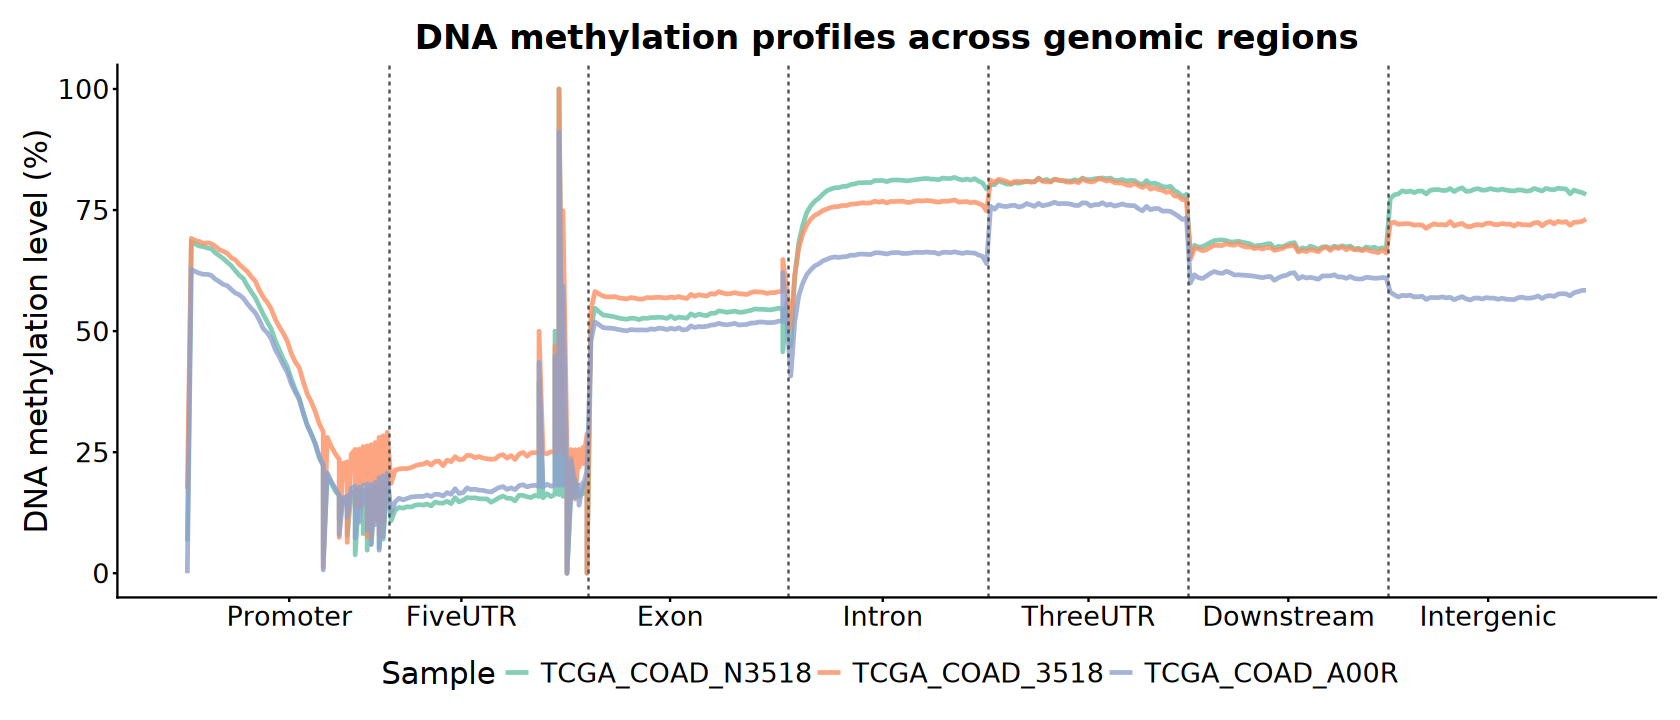

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)

x_labels_pos <- plot_df |> group_by(region) |>
    summarise(center_idx = mean(global_idx), .groups = "drop")
vlines_pos <- seq(50 + 0.5, max(plot_df$global_idx) - 50 + 0.5, by = 50)

ggplot(plot_df, aes(x = global_idx, y = mean, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = vlines_pos, color = "grey30", linetype = "dashed") +
    scale_x_continuous(
        breaks = x_labels_pos$center_idx, 
        labels = x_labels_pos$region) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 1)) +
    labs(
        title = "DNA methylation profiles across genomic regions",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [53]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [54]:
meth_df <- imap_dfr(signals_list, function(gr, sample_id) {
    get_region_data(
        gr = gr, region_list = region_list, method = "mean", 
        meth_col = "score")
}, .id = "sample") |>
    mutate(
        mean = mean * 100, 
        region = factor(region, levels = names(region_list))) |>
    mutate(sample = factor(sample, levels = names(signals_list)))

head(meth_df)

sample,region,numCpG,mean
<fct>,<fct>,<int>,<dbl>
TCGA_COAD_N3518,CGI,1689005,16.91534
TCGA_COAD_N3518,CGI_Shore,1449055,56.61023
TCGA_COAD_N3518,CGI_Shelf,911123,79.53871
TCGA_COAD_N3518,Promoter,2264189,31.58553
TCGA_COAD_N3518,Exon,5941920,53.40599
TCGA_COAD_N3518,Intron,123058273,78.38769


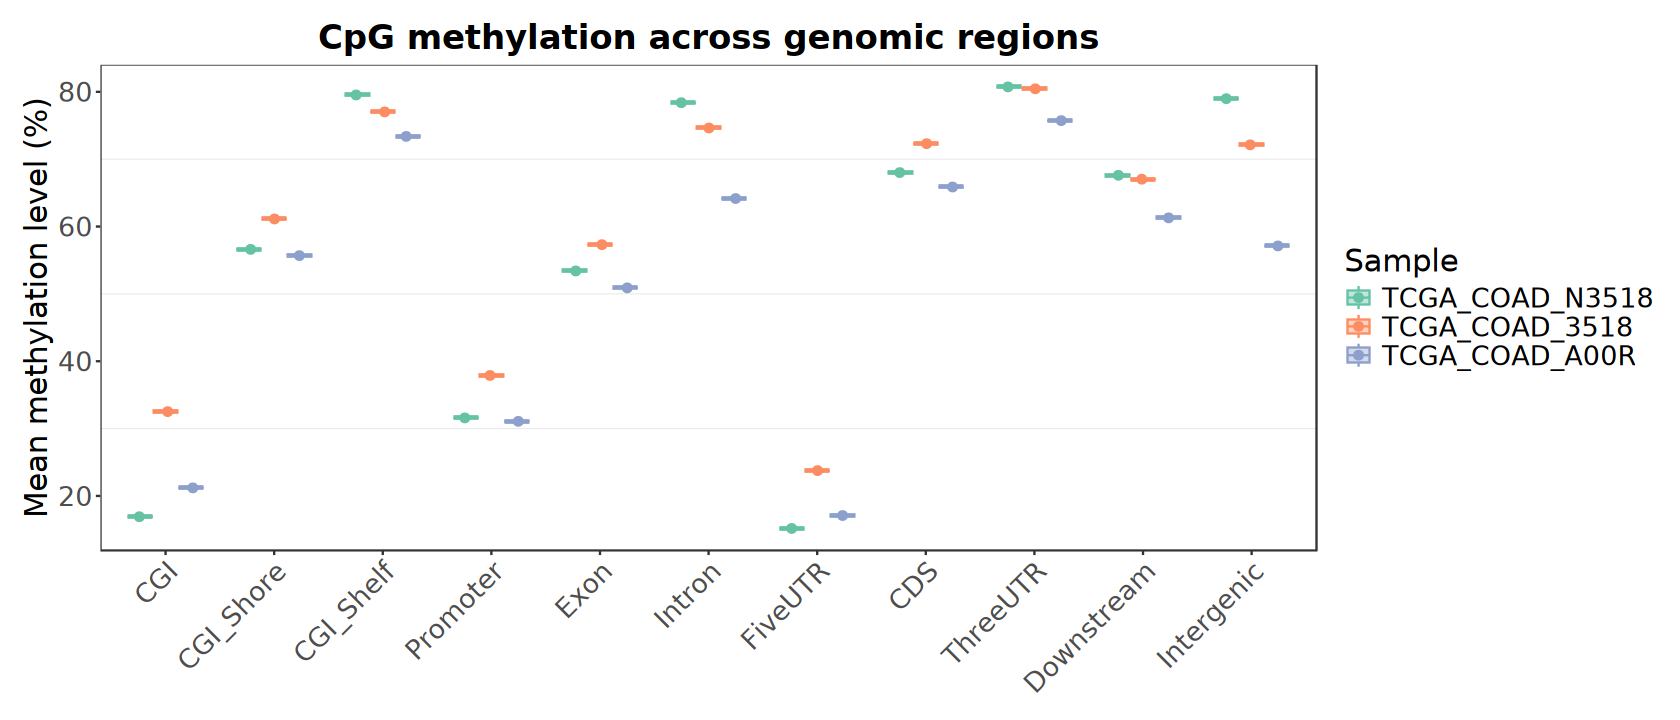

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_boxplot(
        aes(color = sample, fill = sample), 
        position = position_dodge(width = 0.7),
        width = 0.7, outlier.shape = NA, alpha = 0.4) +
    geom_point(
        aes(color = sample), 
        position = position_jitterdodge(
            jitter.width = 0.1, dodge.width = 0.7), 
        size = 2, alpha = 1) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Sample", fill = "Sample") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

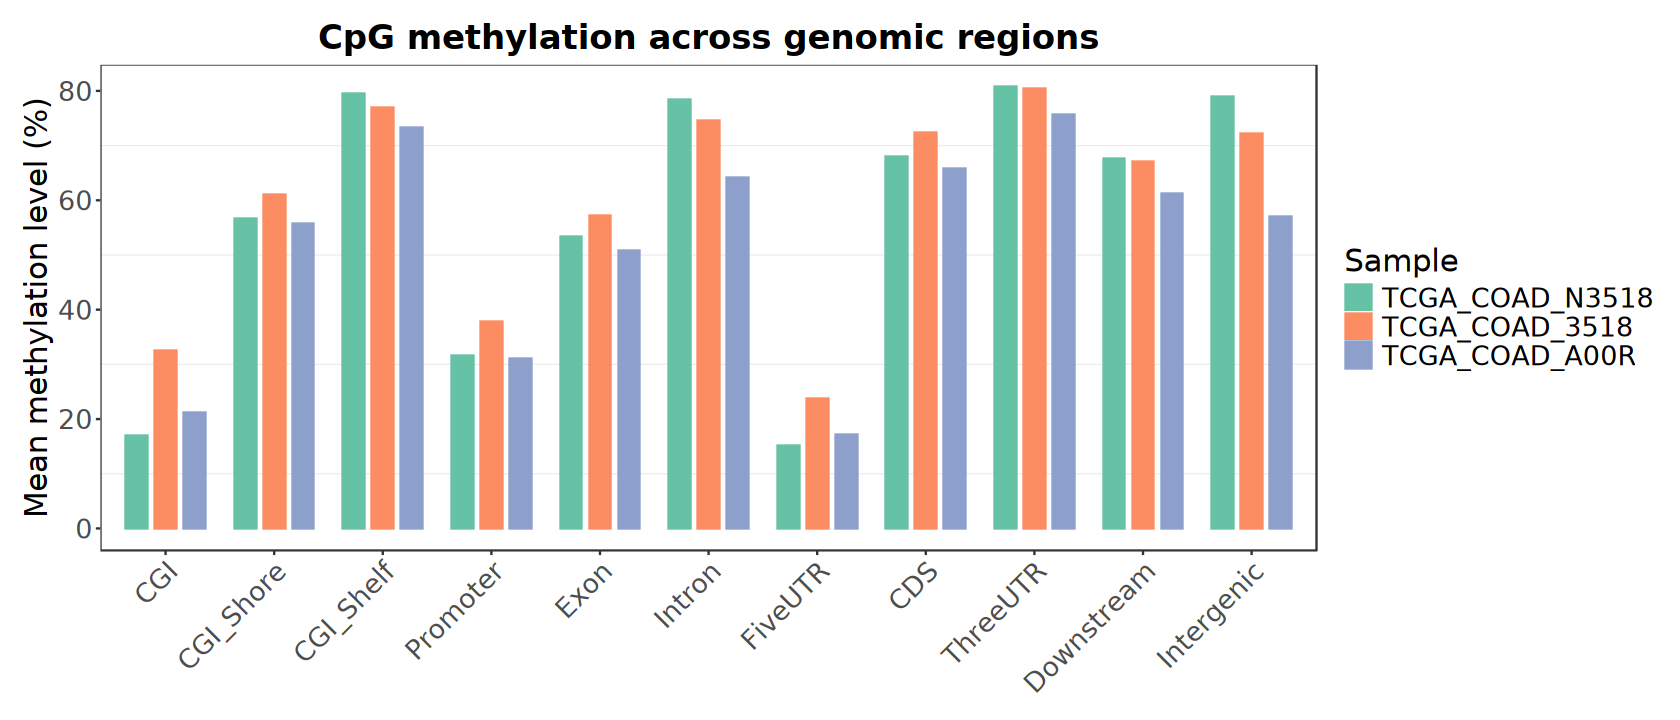

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean, color = sample, fill = sample)) +
    geom_bar(
        stat = "summary", fun = "mean", width = 0.6, 
        position = position_dodge(width = 0.8)) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black",
        position = position_dodge(width = 0.8), width = 0.2) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Sample", fill = "Sample") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# * Reference